# Predictive Maintenance for Water Pumps Using Machine Learning and Deep Learning

**Dataset:** [Pump Sensor Data](https://www.kaggle.com/datasets/nphantawee/pump-sensor-data) (Kaggle)

**Task type:** Time-series classification for predictive maintenance.

**Motivation:** Unplanned pump failures are costly and disruptive. A model that can flag an
*anomalous* operating state (a temporary malfunction that self-recovers, or an outright
failure) before or as it happens gives maintenance teams a window to intervene, reducing
downtime and repair cost.

**Original target — `machine_status` (3 classes):**

| Class | Meaning | Approx. count | Approx. % |
|---|---|---|---|
| `NORMAL` | steady-state operation | ~205,836 | ~93.4% |
| `RECOVERING` | temporary malfunction, auto-recovers | ~14,477 | ~6.6% |
| `BROKEN` | actual failure — needs maintenance | ~7 | ~0.003% |

`BROKEN` is so rare (7 rows out of 220,320) that no classifier can learn a separate decision
boundary for it, and any train/test split risks leaving it with zero examples on one side.
Following common practice for this dataset (and as suggested in the assessment brief), we
**reframe the problem as binary anomaly detection**:

* **Class 0 — `NORMAL`**
* **Class 1 — `ANOMALY`** = `RECOVERING` + `BROKEN`

This keeps the evaluation meaningful while preserving the real-world extreme class
imbalance (~6.6% positive class), which is itself a central discussion point: **accuracy is
misleading on this dataset** (predicting "NORMAL" for every row already scores ~93.4%
accuracy), so we lean on **precision, recall, F1-score, ROC-AUC and PR-AUC** for the anomaly
class, and use **class weighting** to counter the imbalance during training.

**Models compared:**

* Classical ML (tabular, per-timestep features): Decision Tree, Random Forest, Naïve Bayes
* Deep Learning (tabular, per-timestep features): Multilayer ANN (MLP)
* Deep Learning (sequential): LSTM, using rolling windows of past sensor readings

**Notebook structure** (mirrors the presentation outline):
1. Data loading
2. Dataset description & exploratory analysis
3. Data cleaning & preprocessing
4. Binary target creation & time-based train/test split
5. Feature engineering (rolling statistics, scaling)
6. Model training: Decision Tree, Random Forest, Naïve Bayes, ANN
7. Model evaluation (Accuracy, Precision, Recall, F1, Confusion Matrix, ROC-AUC, PR-AUC)
8. Sequence preparation & LSTM
9. Model comparison
10. Conclusion & discussion
11. References (APA)


## 1. Imports & configuration

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight, compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

print('TensorFlow version:', tf.__version__)


TensorFlow version: 2.21.0


## 2. Load data

The raw file is `sensor.csv`: ~220k rows recorded at 1-minute intervals from
1 April 2018 to 31 August 2018, with 52 sensor columns (`sensor_00` … `sensor_51`), a
`timestamp` column and the `machine_status` label.

In [2]:
df = pd.read_csv('sensor.csv')
df = df.drop(columns=['Unnamed: 0'])  # redundant row index saved by the original export
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

print('Shape:', df.shape)
df.head()


Shape: (220320, 54)


,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
0,2018-04-01 00:00:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,15.56713,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
1,2018-04-01 00:01:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,15.56713,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
2,2018-04-01 00:02:00,2.444734,47.35243,53.2118,46.397570,638.8889,73.54598,13.32465,16.03733,15.61777,...,41.66666,39.351852,65.39352,51.21528,38.194443,155.9606,67.12963,241.3194,203.7037,NORMAL
3,2018-04-01 00:03:00,2.460474,47.09201,53.1684,46.397568,628.1250,76.98898,13.31742,16.24711,15.69734,...,40.88541,39.062500,64.81481,51.21528,38.194440,155.9606,66.84028,240.4514,203.1250,NORMAL
4,2018-04-01 00:04:00,2.445718,47.13541,53.2118,46.397568,636.4583,76.58897,13.35359,16.21094,15.69734,...,41.40625,38.773150,65.10416,51.79398,38.773150,158.2755,66.55093,242.1875,201.3889,NORMAL


## 3. Dataset description & exploratory analysis

In [3]:
print(f"Time span: {df['timestamp'].min()}  ->  {df['timestamp'].max()}")
print(f"Number of rows: {len(df):,}")
print(f"Number of sensor columns: {df.columns.str.startswith('sensor_').sum()}")
df.info()


Time span: 2018-04-01 00:00:00  ->  2018-08-31 23:59:00
Number of rows: 220,320
Number of sensor columns: 52
<class 'pandas.DataFrame'>
RangeIndex: 220320 entries, 0 to 220319
Data columns (total 54 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   timestamp       220320 non-null  datetime64[us]
 1   sensor_00       210112 non-null  float64       
 2   sensor_01       219951 non-null  float64       
 3   sensor_02       220301 non-null  float64       
 4   sensor_03       220301 non-null  float64       
 5   sensor_04       220301 non-null  float64       
 6   sensor_05       220301 non-null  float64       
 7   sensor_06       215522 non-null  float64       
 8   sensor_07       214869 non-null  float64       
 9   sensor_08       215213 non-null  float64       
 10  sensor_09       215725 non-null  float64       
 11  sensor_10       220301 non-null  float64       
 12  sensor_11       220301 non-null  float64    

                 count  percent
machine_status                 
NORMAL          205836   93.426
RECOVERING       14477    6.571
BROKEN               7    0.003


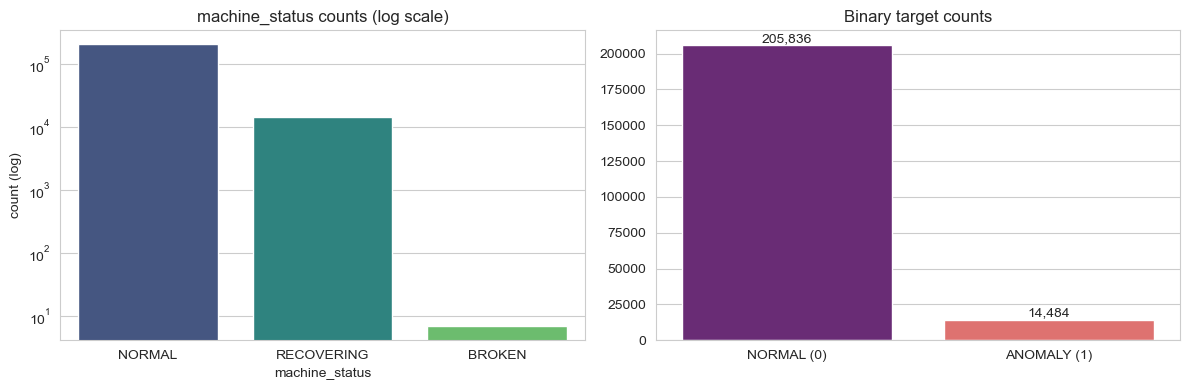

\nBinary class balance -> NORMAL: 205,836 (93.43%), ANOMALY: 14,484 (6.57%)


In [4]:
status_counts = df['machine_status'].value_counts()
status_pct = df['machine_status'].value_counts(normalize=True) * 100
summary = pd.DataFrame({'count': status_counts, 'percent': status_pct.round(3)})
print(summary)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=summary.index, y=summary['count'], ax=ax[0], palette='viridis')
ax[0].set_yscale('log')
ax[0].set_title('machine_status counts (log scale)')
ax[0].set_ylabel('count (log)')

df['anomaly_preview'] = df['machine_status'].isin(['RECOVERING', 'BROKEN']).astype(int)
binary_counts = df['anomaly_preview'].value_counts()
sns.barplot(x=['NORMAL (0)', 'ANOMALY (1)'], y=binary_counts.values, ax=ax[1], palette='magma')
ax[1].set_title('Binary target counts')
for i, v in enumerate(binary_counts.values):
    ax[1].text(i, v, f'{v:,}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

print(f"\\nBinary class balance -> NORMAL: {binary_counts[0]:,} ({binary_counts[0]/len(df)*100:.2f}%), "
      f"ANOMALY: {binary_counts[1]:,} ({binary_counts[1]/len(df)*100:.2f}%)")
df = df.drop(columns=['anomaly_preview'])


**Observation:** `NORMAL` dominates the dataset (~93%). Even after merging
`RECOVERING`+`BROKEN` into a single `ANOMALY` class, the positive class is still only
~6.6% of the data — this is an **extreme class imbalance** problem, and it is the single
most important characteristic to discuss when interpreting model results below.

           missing_count  missing_pct
sensor_15         220320       100.00
sensor_50          77017        34.96
sensor_51          15383         6.98
sensor_00          10208         4.63
sensor_07           5451         2.47
sensor_08           5107         2.32
sensor_06           4798         2.18
sensor_09           4595         2.09
sensor_01            369         0.17
sensor_30            261         0.12
sensor_29             72         0.03
sensor_32             68         0.03
sensor_18             46         0.02
sensor_17             46         0.02
sensor_22             41         0.02
sensor_25             36         0.02
sensor_16             31         0.01
sensor_41             27         0.01
sensor_39             27         0.01
sensor_40             27         0.01
sensor_42             27         0.01
sensor_38             27         0.01
sensor_43             27         0.01
sensor_44             27         0.01
sensor_45             27         0.01
sensor_46   

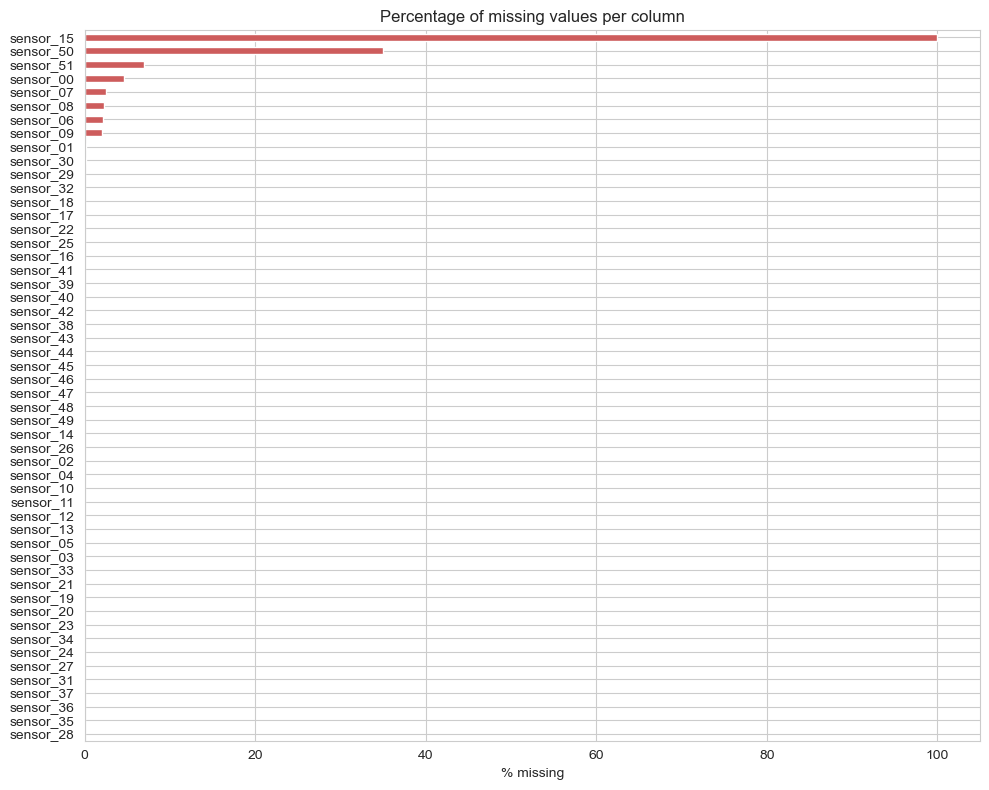

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
print(missing_summary)

fig, ax = plt.subplots(figsize=(10, 8))
missing_summary['missing_pct'].plot(kind='barh', ax=ax, color='indianred')
ax.set_title('Percentage of missing values per column')
ax.set_xlabel('% missing')
ax.invert_yaxis()
plt.tight_layout()
plt.show()


`sensor_15` is **100% missing** (a known artefact of this dataset — the sensor never
recorded a value) and will be dropped entirely. `sensor_50` and `sensor_51` have high
missingness (~35% and ~7% respectively); a handful of other sensors have small numbers of
missing values (< 5%). Because these are continuous physical readings sampled once per
minute, we treat missingness as short sensor dropouts and use **time-based interpolation**
rather than a single global mean/median fill.

Total sensor columns before cleaning: 52


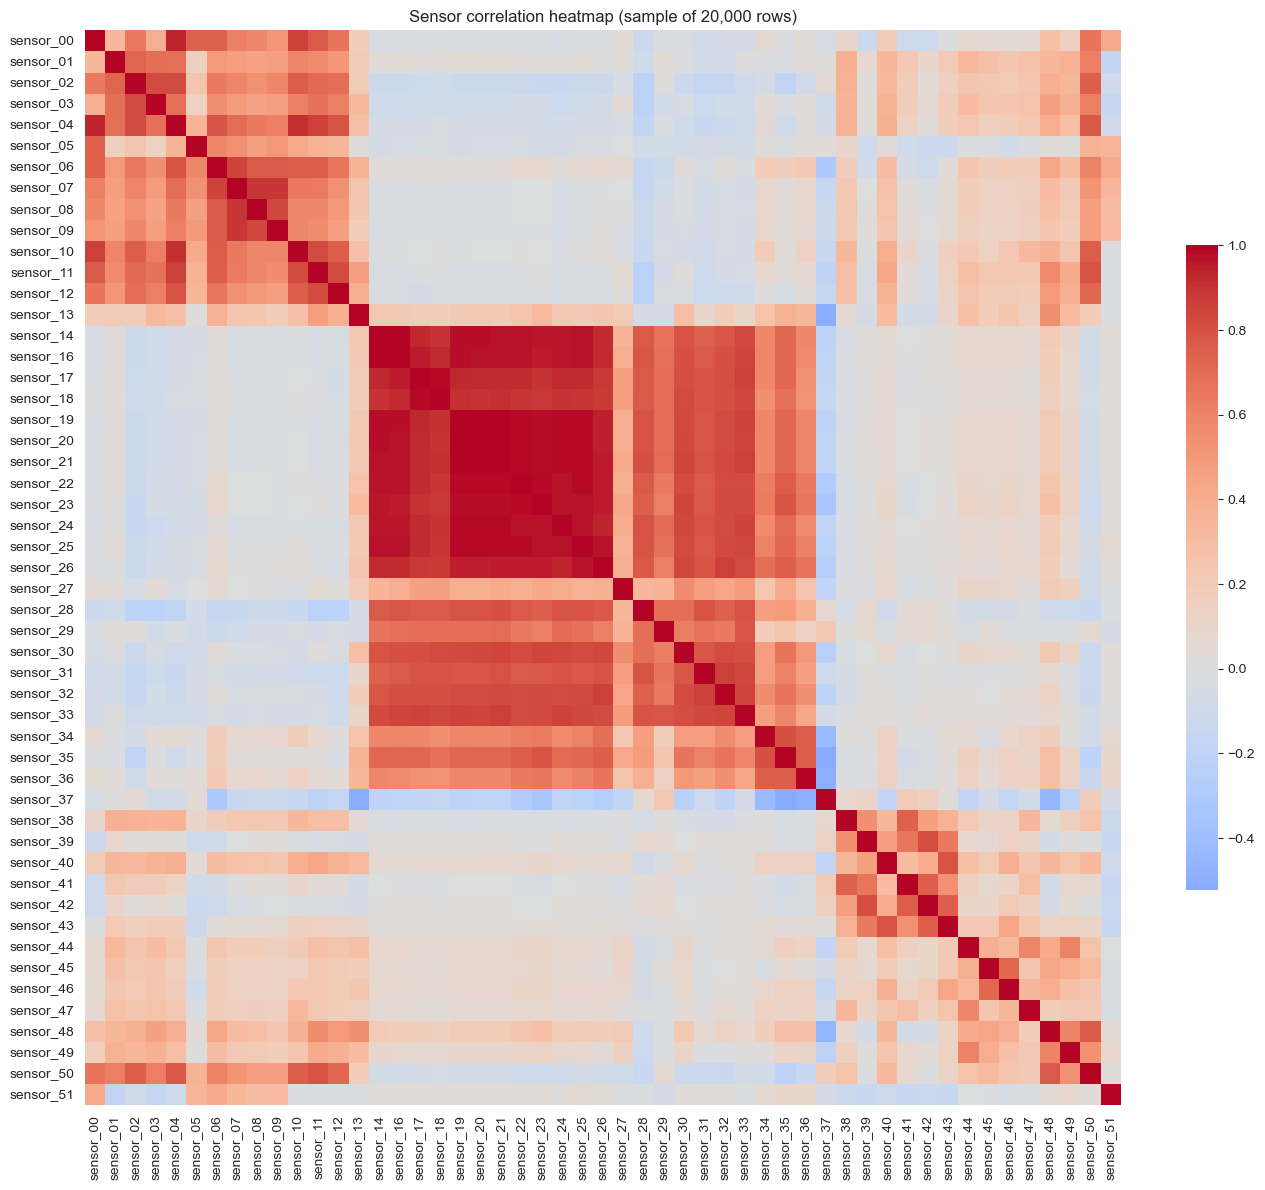

In [6]:
sensor_cols_all = [c for c in df.columns if c.startswith('sensor_')]
print(f'Total sensor columns before cleaning: {len(sensor_cols_all)}')

# Correlation heatmap on a random sample of rows (for speed / readability)
sample_df = df[sensor_cols_all].drop(columns=['sensor_15']).sample(20000, random_state=RANDOM_STATE)
corr = sample_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, cbar_kws={'shrink': 0.6})
plt.title('Sensor correlation heatmap (sample of 20,000 rows)')
plt.tight_layout()
plt.show()


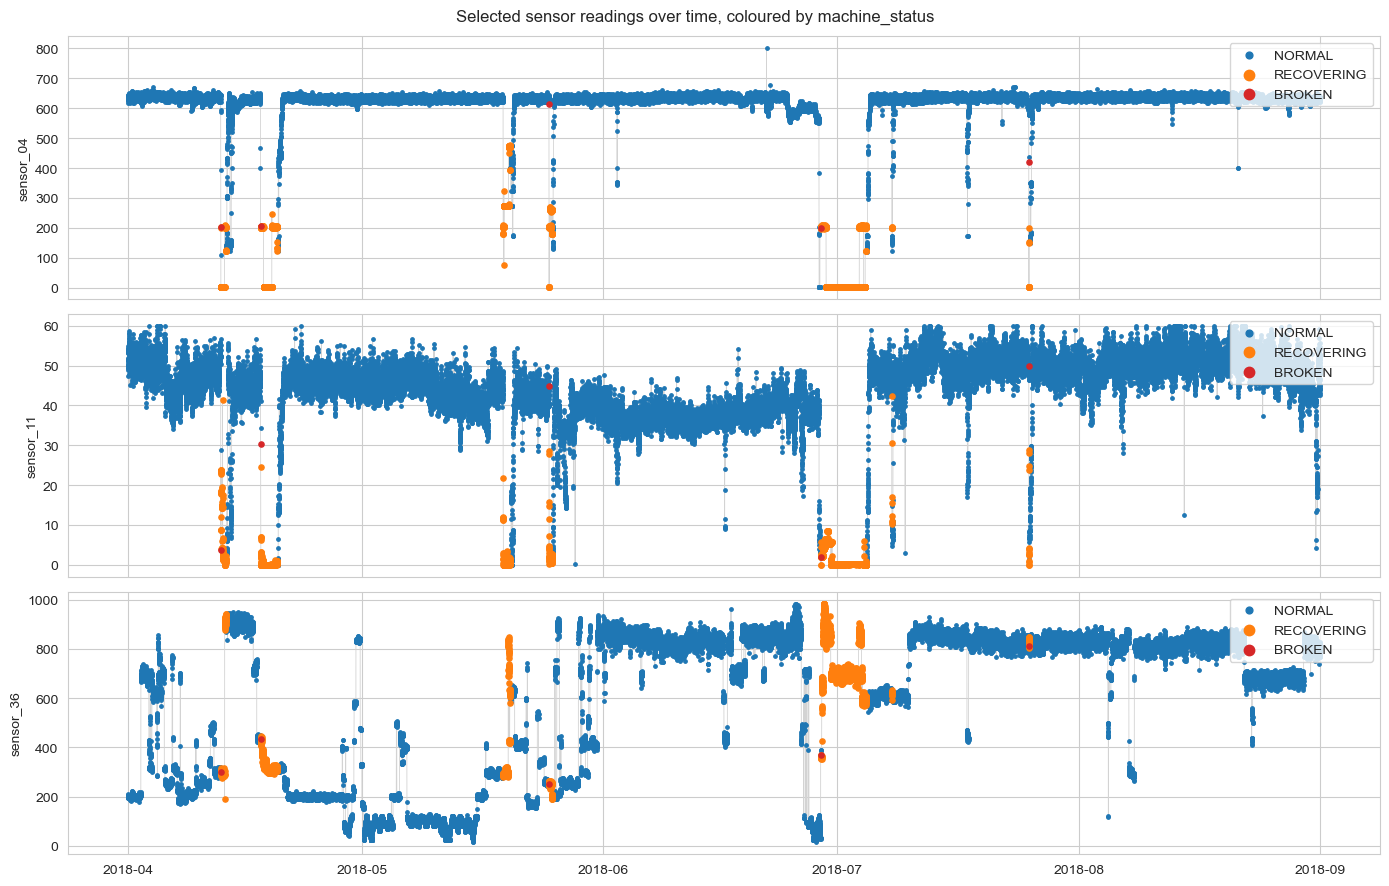

In [7]:
# Visualise a few representative sensors over time, coloured by machine status
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
plot_sensors = ['sensor_04', 'sensor_11', 'sensor_36']
status_colors = {'NORMAL': 'tab:blue', 'RECOVERING': 'tab:orange', 'BROKEN': 'tab:red'}

plot_df = df.iloc[::5]  # subsample every 5th row purely for plotting speed
for ax, s in zip(axes, plot_sensors):
    ax.plot(plot_df['timestamp'], plot_df[s], color='lightgray', linewidth=0.6, zorder=1)
    for status, color in status_colors.items():
        mask = plot_df['machine_status'] == status
        if mask.any():
            ax.scatter(plot_df.loc[mask, 'timestamp'], plot_df.loc[mask, s],
                       s=6 if status == 'NORMAL' else 14, color=color, label=status, zorder=2)
    ax.set_ylabel(s)
    ax.legend(loc='upper right', markerscale=2)
plt.suptitle('Selected sensor readings over time, coloured by machine_status')
plt.tight_layout()
plt.show()


## 4. Data cleaning

1. Drop `sensor_15` (100% missing — no information).
2. Impute remaining missing values with **time-based linear interpolation**, then
   forward/backward-fill any values still missing at the very start/end of the series.
3. Clip extreme outliers in each sensor to the **[0.1, 99.9] percentile range** (computed on
   the training split only, see Section 6) to reduce noise from spikes/sensor glitches
   without destroying real anomalies (anomalies tend to appear as *sustained* shifts, not
   single-point spikes, so light percentile clipping is safe here).

In [8]:
df_clean = df.drop(columns=['sensor_15']).copy()
sensor_cols = [c for c in df_clean.columns if c.startswith('sensor_')]
print(f'Sensor columns after dropping sensor_15: {len(sensor_cols)}')

# Time-based interpolation (uses timestamp order, already sorted)
df_clean[sensor_cols] = df_clean[sensor_cols].interpolate(method='linear', limit_direction='both')

remaining_na = df_clean[sensor_cols].isna().sum().sum()
print(f'Remaining missing values after interpolation: {remaining_na}')


Sensor columns after dropping sensor_15: 51
Remaining missing values after interpolation: 0


In [9]:
df_clean['anomaly'] = df_clean['machine_status'].isin(['RECOVERING', 'BROKEN']).astype(int)

print(df_clean[['machine_status', 'anomaly']].drop_duplicates())
print()
print(df_clean['anomaly'].value_counts())


      machine_status  anomaly
0             NORMAL        0
17155         BROKEN        1
17156     RECOVERING        1

anomaly
0    205836
1     14484
Name: count, dtype: int64


## 5. Time-based train/test split

Because this is time-series data, we split **chronologically** rather than randomly, which
avoids "leaking" future information into training and reflects how the model would actually
be deployed (train on the past, predict the future). A naive "first 80% / last 20%" split
turns out to be a trap on this dataset: every anomaly episode (`RECOVERING`/`BROKEN`) occurs
between **12 April and 25 July 2018** — the entire month of **August is 100% `NORMAL`**. A
last-20%-of-rows split lands almost entirely inside August, producing a test set with
**zero** positive examples, which makes Precision/Recall/F1/ROC-AUC/PR-AUC all undefined —
not a useful evaluation at all.

Instead, we split on a fixed date, **1 July 2018**, chosen so both partitions contain real
anomalies (including several of the 7 `BROKEN` events on each side):

* **Train:** April – June (contains 5 of the 7 `BROKEN` events)
* **Test:** July – August (contains the remaining 2 `BROKEN` events, plus all of the
  anomaly-free August data — a realistic "quiet period" the model must not falsely flag)

This is a larger test window (~40% of the timeline) than a typical 80/20 split, but it is
the smallest test window that still gives a meaningful evaluation of the positive class on
this particular dataset.

In [10]:
split_date = pd.Timestamp('2018-07-01')

train_df = df_clean[df_clean['timestamp'] < split_date].reset_index(drop=True)
test_df = df_clean[df_clean['timestamp'] >= split_date].reset_index(drop=True)
split_idx = len(train_df)  # row index of the split, used later for the LSTM sequence split

print(f'Split date: {split_date}')
print(f'Train: {len(train_df):,} rows  ({train_df["timestamp"].min()} -> {train_df["timestamp"].max()})')
print(f'Test:  {len(test_df):,} rows  ({test_df["timestamp"].min()} -> {test_df["timestamp"].max()})')
print()
for name, d in [('Train', train_df), ('Test', test_df)]:
    vc = d['anomaly'].value_counts(normalize=True) * 100
    print(f'{name} anomaly rate: {vc.get(1, 0):.2f}%   (NORMAL: {vc.get(0, 0):.2f}%)')
print()
print('machine_status breakdown in test set:')
print(test_df['machine_status'].value_counts())


Split date: 2018-07-01 00:00:00
Train: 131,040 rows  (2018-04-01 00:00:00 -> 2018-06-30 23:59:00)
Test:  89,280 rows  (2018-07-01 00:00:00 -> 2018-08-31 23:59:00)

Train anomaly rate: 6.85%   (NORMAL: 93.15%)
Test anomaly rate: 6.17%   (NORMAL: 93.83%)

machine_status breakdown in test set:
machine_status
NORMAL        83771
RECOVERING     5507
BROKEN            2
Name: count, dtype: int64


**Note:** `BROKEN` now has examples on both sides of the split (5 in train, 2 in test),
and the test set's 6.17% anomaly rate — lower than the training set's 6.85% because roughly
half of the test window (all of August) is anomaly-free — is itself a realistic feature of
predictive-maintenance data: the model must stay quiet during long normal stretches while
still catching the anomalies that do occur.

## 6. Feature engineering

For the classical/tabular models, each row (timestamp) is treated as an independent sample
described by:

* the **51 raw sensor readings** (after dropping `sensor_15`), and
* **rolling statistics** (5-minute rolling mean & standard deviation per sensor), which give
  each model a small amount of short-term temporal context — a sudden jump in the rolling
  standard deviation is often a stronger signal of an incipient fault than the instantaneous
  reading alone.

Rolling windows only look **backwards** in time, so they introduce no leakage across the
train/test boundary.

Outlier clipping bounds and the feature scaler are **fit on the training split only** and
then applied to the test split, to avoid any information leaking from test into train.

In [11]:
def add_rolling_features(data, cols, window=5):
    roll = data[cols].rolling(window=window, min_periods=1)
    means = roll.mean().add_suffix(f'_roll{window}_mean')
    stds = roll.std().add_suffix(f'_roll{window}_std').fillna(0.0)
    return pd.concat([data, means, stds], axis=1)

train_feat = add_rolling_features(train_df, sensor_cols, window=5)
test_feat = add_rolling_features(test_df, sensor_cols, window=5)

feature_cols = sensor_cols + [c for c in train_feat.columns if '_roll5_' in c]
print(f'Total tabular feature count: {len(feature_cols)}')


Total tabular feature count: 153


In [12]:
# Outlier clipping — bounds learned from TRAIN only, applied to both splits
lower = train_feat[feature_cols].quantile(0.001)
upper = train_feat[feature_cols].quantile(0.999)

train_feat[feature_cols] = train_feat[feature_cols].clip(lower=lower, upper=upper, axis=1)
test_feat[feature_cols] = test_feat[feature_cols].clip(lower=lower, upper=upper, axis=1)

X_train = train_feat[feature_cols].values
y_train = train_feat['anomaly'].values
X_test = test_feat[feature_cols].values
y_test = test_feat['anomaly'].values

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('X_train:', X_train_scaled.shape, ' X_test:', X_test_scaled.shape)


X_train: (131040, 153)  X_test: (89280, 153)


In [13]:
# Class weights, used across all classical + ANN models to counter the ~93/7 imbalance
class_weights_arr = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight_dict = {0: class_weights_arr[0], 1: class_weights_arr[1]}
sample_weights_train = compute_sample_weight('balanced', y_train)
print('Class weights (0=NORMAL, 1=ANOMALY):', class_weight_dict)


Class weights (0=NORMAL, 1=ANOMALY): {0: np.float64(0.5367631999344612), 1: np.float64(7.300278551532034)}


## 7. Evaluation utilities

A single helper computes every metric requested in the brief — **Accuracy, Precision,
Recall, F1-score, Confusion Matrix, ROC-AUC and PR-AUC** — and plots the confusion matrix,
ROC curve and Precision-Recall curve. Precision/Recall/F1 are reported for the **anomaly
(positive) class**, since that is the class that matters for predictive maintenance and the
one accuracy alone would hide.

Results from every model are collected into `results` for the final comparison table.

In [14]:
results = {}

def evaluate_model(name, y_true, y_pred, y_proba):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    rec = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_proba)
    pr_auc = average_precision_score(y_true, y_proba)

    results[name] = {
        'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1,
        'ROC-AUC': roc_auc, 'PR-AUC': pr_auc,
    }

    print(f'===== {name} =====')
    print(classification_report(y_true, y_pred, target_names=['NORMAL', 'ANOMALY'], zero_division=0))
    print(f'ROC-AUC: {roc_auc:.4f}   PR-AUC: {pr_auc:.4f}')

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[0],
                xticklabels=['NORMAL', 'ANOMALY'], yticklabels=['NORMAL', 'ANOMALY'])
    axes[0].set_title(f'{name} — Confusion Matrix')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Actual')

    fpr, tpr, _ = roc_curve(y_true, y_proba)
    axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}', color='darkorange')
    axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
    axes[1].set_title(f'{name} — ROC Curve')
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].legend(loc='lower right')

    prec_curve, rec_curve, _ = precision_recall_curve(y_true, y_proba)
    baseline = y_true.mean()
    axes[2].plot(rec_curve, prec_curve, label=f'AP = {pr_auc:.3f}', color='seagreen')
    axes[2].axhline(baseline, linestyle='--', color='gray', label=f'baseline = {baseline:.3f}')
    axes[2].set_title(f'{name} — Precision-Recall Curve')
    axes[2].set_xlabel('Recall')
    axes[2].set_ylabel('Precision')
    axes[2].legend(loc='upper right')

    plt.tight_layout()
    plt.show()

    return results[name]


## 8. Model 1 — Decision Tree

A shallow, interpretable baseline. `class_weight='balanced'` re-weights the loss so the
rare anomaly class is not ignored; `max_depth` is limited to reduce overfitting given how
few truly informative anomaly examples exist.

===== Decision Tree =====
              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00     83771
     ANOMALY       0.98      0.99      0.99      5509

    accuracy                           1.00     89280
   macro avg       0.99      0.99      0.99     89280
weighted avg       1.00      1.00      1.00     89280

ROC-AUC: 0.9952   PR-AUC: 0.9823


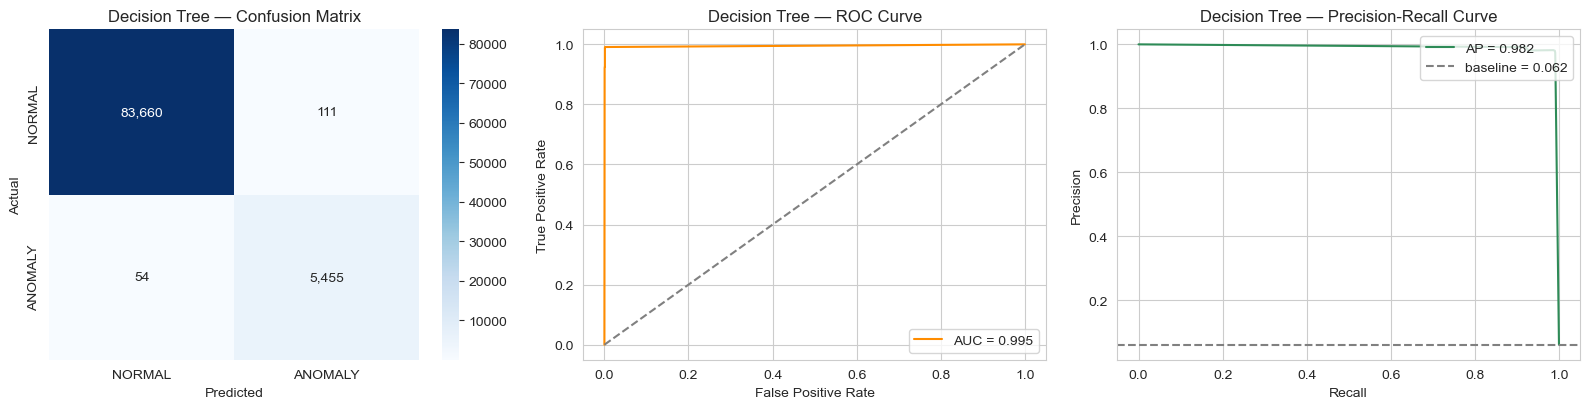

{'Accuracy': 0.9981518817204301,
 'Precision': 0.9800574919151994,
 'Recall': 0.9901978580504629,
 'F1': 0.9851015801354401,
 'ROC-AUC': 0.9952156021537671,
 'PR-AUC': 0.9822947608132611}

In [15]:
dt_model = DecisionTreeClassifier(
    max_depth=10, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE
)
dt_model.fit(X_train_scaled, y_train)

dt_pred = dt_model.predict(X_test_scaled)
dt_proba = dt_model.predict_proba(X_test_scaled)[:, 1]
evaluate_model('Decision Tree', y_test, dt_pred, dt_proba)


## 9. Model 2 — Random Forest

An ensemble of trees; typically a strong tabular baseline that handles non-linear
interactions between sensors better than a single tree, at the cost of interpretability
(mitigated somewhat by feature importances, below).

===== Random Forest =====
              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00     83771
     ANOMALY       0.98      0.99      0.98      5509

    accuracy                           1.00     89280
   macro avg       0.99      1.00      0.99     89280
weighted avg       1.00      1.00      1.00     89280

ROC-AUC: 0.9999   PR-AUC: 0.9989


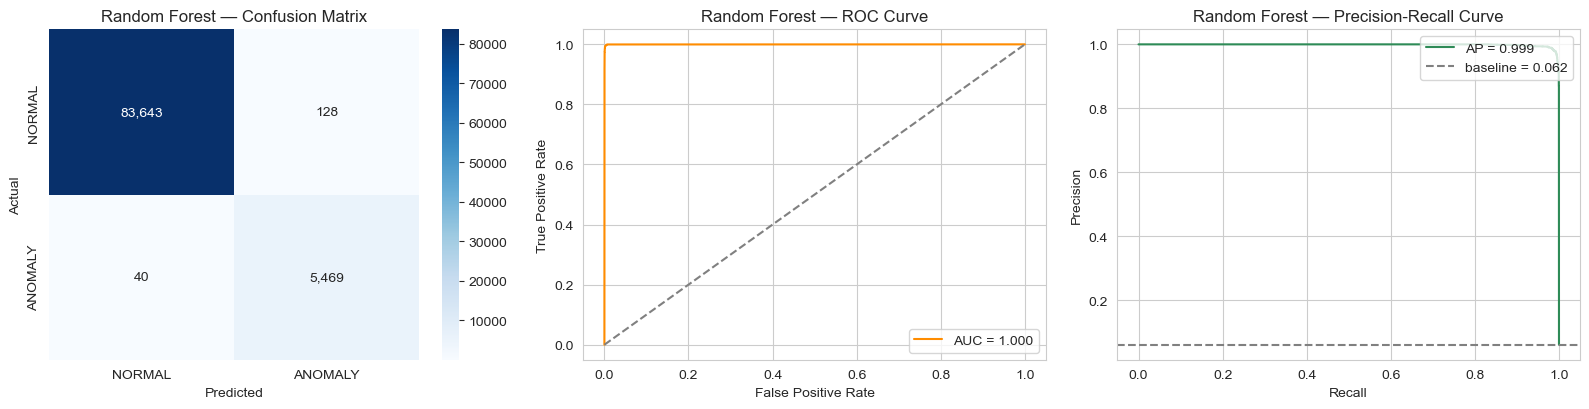

{'Accuracy': 0.9981182795698925,
 'Precision': 0.9771306056816151,
 'Recall': 0.992739154111454,
 'F1': 0.9848730415991356,
 'ROC-AUC': 0.9999252407026296,
 'PR-AUC': 0.9988629673751416}

In [16]:
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=15, min_samples_leaf=5,
    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE
)
rf_model.fit(X_train_scaled, y_train)

rf_pred = rf_model.predict(X_test_scaled)
rf_proba = rf_model.predict_proba(X_test_scaled)[:, 1]
evaluate_model('Random Forest', y_test, rf_pred, rf_proba)


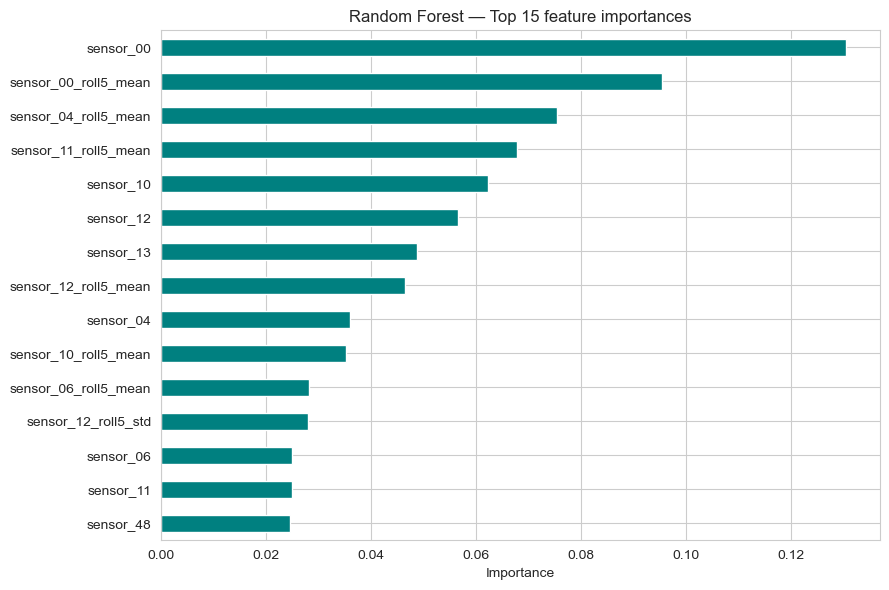

sensor_00               0.130412
sensor_00_roll5_mean    0.095399
sensor_04_roll5_mean    0.075324
sensor_11_roll5_mean    0.067873
sensor_10               0.062193
sensor_12               0.056455
sensor_13               0.048677
sensor_12_roll5_mean    0.046386
sensor_04               0.036042
sensor_10_roll5_mean    0.035256
sensor_06_roll5_mean    0.028111
sensor_12_roll5_std     0.027906
sensor_06               0.024958
sensor_11               0.024881
sensor_48               0.024556
dtype: float64


In [17]:
# Feature importance — which sensors (and rolling stats) drive the Random Forest's decisions
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
top_n = 15

plt.figure(figsize=(9, 6))
importances.head(top_n).iloc[::-1].plot(kind='barh', color='teal')
plt.title(f'Random Forest — Top {top_n} feature importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(importances.head(top_n))


Several published analyses of this dataset (e.g. community Kaggle notebooks) also
highlight `sensor_26`, `sensor_48`, `sensor_31` and `sensor_29` as informative — it's worth
checking in the printed list above whether our Random Forest agrees, and discussing any
differences (driven by our added rolling features, or by the specific train/test split) in
the presentation.

## 10. Model 3 — Naïve Bayes

Gaussian Naïve Bayes assumes features are conditionally independent given the class — an
assumption clearly violated here (many sensors are physically correlated, e.g. temperature
and pressure), so this model is included mainly as a **contrast**: it shows what happens
when a model ignores feature correlations entirely. `GaussianNB` does not accept
`class_weight`, so we pass `sample_weight` at fit time to achieve the same effect.

===== Naive Bayes =====
              precision    recall  f1-score   support

      NORMAL       1.00      0.99      1.00     83771
     ANOMALY       0.88      0.99      0.93      5509

    accuracy                           0.99     89280
   macro avg       0.94      0.99      0.96     89280
weighted avg       0.99      0.99      0.99     89280

ROC-AUC: 0.9948   PR-AUC: 0.8833


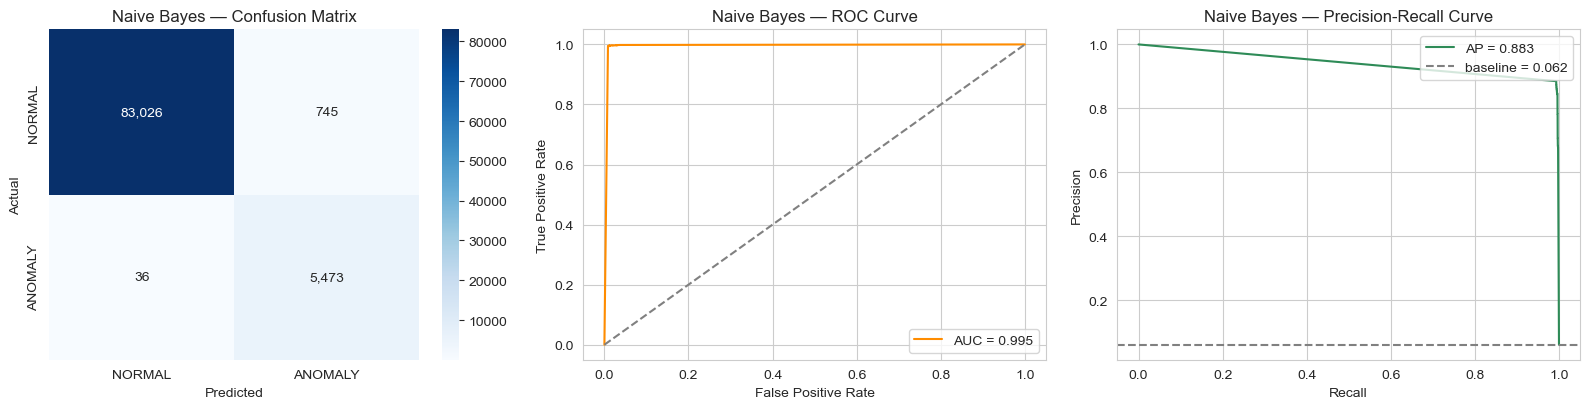

{'Accuracy': 0.9912522401433692,
 'Precision': 0.8801865551624316,
 'Recall': 0.9934652387003086,
 'F1': 0.9334015519740769,
 'ROC-AUC': 0.9947664006412872,
 'PR-AUC': 0.8832819418390137}

In [18]:
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train, sample_weight=sample_weights_train)

nb_pred = nb_model.predict(X_test_scaled)
nb_proba = nb_model.predict_proba(X_test_scaled)[:, 1]
evaluate_model('Naive Bayes', y_test, nb_pred, nb_proba)


## 11. Model 4 — Artificial Neural Network (MLP)

A small multilayer perceptron (Dense → Dropout → Dense → Dropout → sigmoid output) trained
directly on the 150-dimensional scaled tabular feature vector, using the same class
weighting strategy as the classical models and early stopping on a held-out validation
slice (the final 10% of the *training* timeline) to prevent overfitting.

In [19]:
val_split_idx = int(len(X_train_scaled) * 0.9)
X_tr, X_val = X_train_scaled[:val_split_idx], X_train_scaled[val_split_idx:]
y_tr, y_val = y_train[:val_split_idx], y_train[val_split_idx:]

ann_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid'),
])

ann_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[keras.metrics.AUC(name='auc'), 'accuracy'],
)

early_stop = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=4, restore_best_weights=True)

history = ann_model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=25, batch_size=1024,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1,
)


Epoch 1/25
116/116 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9552 - auc: 0.9894 - loss: 0.1163 - val_accuracy: 0.9708 - val_auc: 0.9955 - val_loss: 0.0965
Epoch 2/25
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9893 - auc: 0.9983 - loss: 0.0290 - val_accuracy: 0.9698 - val_auc: 0.9827 - val_loss: 0.1488
Epoch 3/25
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9921 - auc: 0.9993 - loss: 0.0186 - val_accuracy: 0.9646 - val_auc: 0.9811 - val_loss: 0.1813
Epoch 4/25
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9944 - auc: 0.9996 - loss: 0.0127 - val_accuracy: 0.9415 - val_auc: 0.9795 - val_loss: 0.2374
Epoch 5/25
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9953 - auc: 0.9996 - loss: 0.0112 - val_accuracy: 0.9515 - val_auc: 0.9793 - val_loss: 0.2547


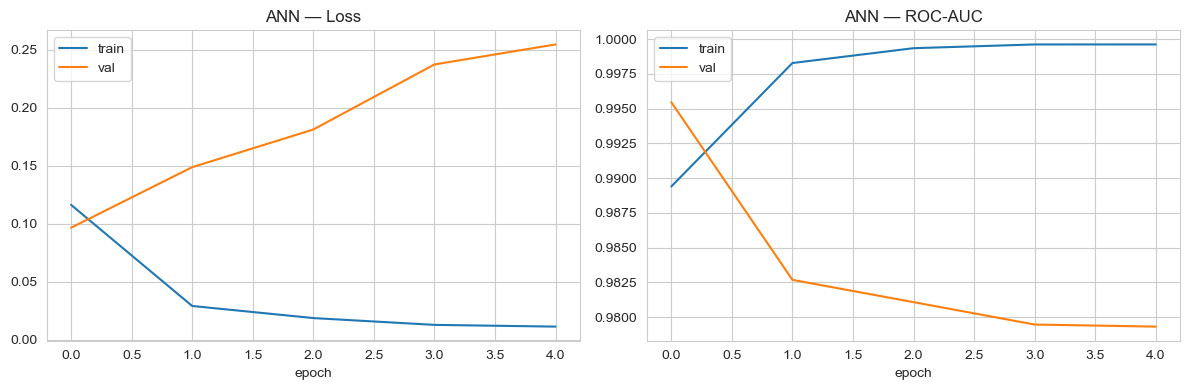

===== ANN (MLP) =====
              precision    recall  f1-score   support

      NORMAL       1.00      0.99      1.00     83771
     ANOMALY       0.92      0.99      0.95      5509

    accuracy                           0.99     89280
   macro avg       0.96      0.99      0.98     89280
weighted avg       0.99      0.99      0.99     89280

ROC-AUC: 0.9993   PR-AUC: 0.9860


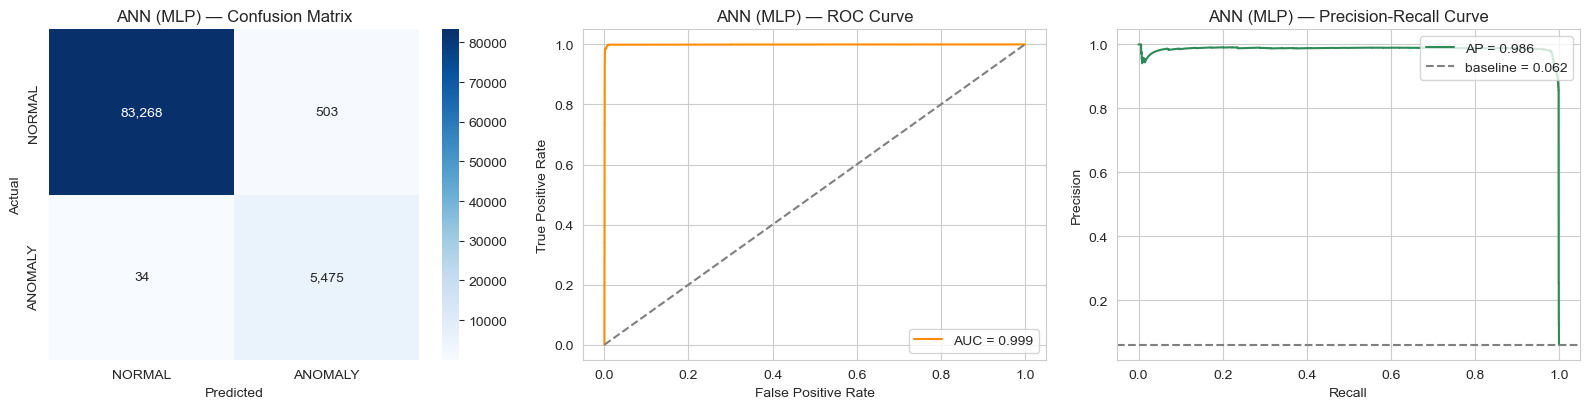

{'Accuracy': 0.9939852150537635,
 'Precision': 0.9158581465373035,
 'Recall': 0.9938282809947359,
 'F1': 0.9532515016975711,
 'ROC-AUC': 0.9992772989838778,
 'PR-AUC': 0.9859624814306167}

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')
axes[0].set_title('ANN — Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(history.history['auc'], label='train')
axes[1].plot(history.history['val_auc'], label='val')
axes[1].set_title('ANN — ROC-AUC'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

ann_proba = ann_model.predict(X_test_scaled, verbose=0).ravel()
ann_pred = (ann_proba >= 0.5).astype(int)
evaluate_model('ANN (MLP)', y_test, ann_pred, ann_proba)


## 12. Preparing sequences for LSTM

Unlike the tabular models above, an LSTM consumes a **window of consecutive past readings**
to make one prediction, which lets it learn temporal patterns (e.g. a sensor drifting over
several minutes before a failure) rather than judging each timestamp in isolation.

* Sequence length **T = 20** minutes.
* Input at time *t*: the raw sensor readings (scaled, no rolling features — the LSTM builds
  its own temporal representation) from *t-T+1* to *t*, shape **(T, 51)**.
* Label at time *t*: `anomaly` at time *t* (i.e. "is the pump in an anomalous state right
  now, given the last 20 minutes of readings").
* Sequences are generated from the full chronological array so that every window only ever
  looks **backwards** in time; a sequence is then assigned to train/validation/test
  according to which split its *label* timestamp falls in — this respects the same
  1 July 2018 time-based split used for the tabular models, so results are directly
  comparable.
* Because a full ~220k x 20 x 51 tensor is unnecessarily large for a class-imbalanced
  demonstration model, we keep **all** anomalous-labelled windows from the training portion
  but randomly **undersample the majority (NORMAL) windows** used for training (a common
  technique for extreme imbalance, alongside the class-weighting used above) — the
  validation and test sets keep every window, so evaluation still reflects the true
  (imbalanced) real-world distribution.

In [21]:
T = 20
lstm_feature_cols = sensor_cols  # raw sensors only, scaled below
full_scaled = StandardScaler().fit(train_df[lstm_feature_cols]).transform(df_clean[lstm_feature_cols])
full_labels = df_clean['anomaly'].values
n = len(df_clean)

# valid window end-indices (need at least T rows of history)
valid_idx = np.arange(T - 1, n)

# assign each candidate index to train / val / test using the SAME time cutoffs as before
val_cutoff_idx = int(len(train_df) * 0.9)   # last 10% of the training timeline -> validation
train_idx = valid_idx[valid_idx < val_cutoff_idx]
val_idx = valid_idx[(valid_idx >= val_cutoff_idx) & (valid_idx < split_idx)]
test_idx = valid_idx[valid_idx >= split_idx]

print(f'Candidate windows -> train: {len(train_idx):,}, val: {len(val_idx):,}, test: {len(test_idx):,}')


Candidate windows -> train: 117,917, val: 13,104, test: 89,280


In [22]:
# Undersample majority-class windows in the TRAINING portion only
rng = np.random.default_rng(RANDOM_STATE)
train_labels_at_idx = full_labels[train_idx]
anomaly_train_idx = train_idx[train_labels_at_idx == 1]
normal_train_idx = train_idx[train_labels_at_idx == 0]

MAX_NORMAL_TRAIN_WINDOWS = 30000
if len(normal_train_idx) > MAX_NORMAL_TRAIN_WINDOWS:
    normal_train_idx = rng.choice(normal_train_idx, size=MAX_NORMAL_TRAIN_WINDOWS, replace=False)

train_idx_sampled = np.sort(np.concatenate([anomaly_train_idx, normal_train_idx]))
rng.shuffle(train_idx_sampled)

print(f'Training windows after undersampling NORMAL: {len(train_idx_sampled):,} '
      f'(anomaly: {len(anomaly_train_idx):,}, normal kept: {len(normal_train_idx):,})')


Training windows after undersampling NORMAL: 35,975 (anomaly: 5,975, normal kept: 30,000)


In [23]:
def build_sequences(end_indices, features, labels, T):
    X = np.empty((len(end_indices), T, features.shape[1]), dtype=np.float32)
    y = np.empty(len(end_indices), dtype=np.float32)
    for i, end in enumerate(end_indices):
        X[i] = features[end - T + 1: end + 1]
        y[i] = labels[end]
    return X, y

X_lstm_train, y_lstm_train = build_sequences(train_idx_sampled, full_scaled, full_labels, T)
X_lstm_val, y_lstm_val = build_sequences(val_idx, full_scaled, full_labels, T)
X_lstm_test, y_lstm_test = build_sequences(test_idx, full_scaled, full_labels, T)

print('X_lstm_train:', X_lstm_train.shape, ' positive rate:', y_lstm_train.mean().round(4))
print('X_lstm_val:  ', X_lstm_val.shape, ' positive rate:', y_lstm_val.mean().round(4))
print('X_lstm_test: ', X_lstm_test.shape, ' positive rate:', y_lstm_test.mean().round(4))


X_lstm_train: (35975, 20, 51)  positive rate: 0.1661
X_lstm_val:   (13104, 20, 51)  positive rate: 0.2289
X_lstm_test:  (89280, 20, 51)  positive rate: 0.0617


## 13. Model 5 — LSTM

Two stacked LSTM layers extract a temporal representation of each 20-minute window, followed
by a small dense head. Class weights (recomputed for the LSTM's own training set, after
undersampling) again counter the residual imbalance, and early stopping on validation
ROC-AUC prevents overfitting.

In [24]:
lstm_class_weights_arr = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_lstm_train)
lstm_class_weight_dict = {0: lstm_class_weights_arr[0], 1: lstm_class_weights_arr[1]}
print('LSTM class weights:', lstm_class_weight_dict)

lstm_model = keras.Sequential([
    layers.Input(shape=(T, len(lstm_feature_cols))),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32, return_sequences=False),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])

lstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[keras.metrics.AUC(name='auc'), 'accuracy'],
)

lstm_early_stop = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=4, restore_best_weights=True)

lstm_history = lstm_model.fit(
    X_lstm_train, y_lstm_train,
    validation_data=(X_lstm_val, y_lstm_val),
    epochs=20, batch_size=256,
    class_weight=lstm_class_weight_dict,
    callbacks=[lstm_early_stop],
    verbose=1,
)


LSTM class weights: {0: np.float64(0.5995833333333334), 1: np.float64(3.010460251046025)}
Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9792 - auc: 0.9959 - loss: 0.0936 - val_accuracy: 0.9761 - val_auc: 0.9975 - val_loss: 0.0717
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9970 - auc: 0.9997 - loss: 0.0105 - val_accuracy: 0.9380 - val_auc: 0.9868 - val_loss: 0.1788
Epoch 3/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9979 - auc: 1.0000 - loss: 0.0061 - val_accuracy: 0.9726 - val_auc: 0.9963 - val_loss: 0.1049
Epoch 4/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9980 - auc: 0.9998 - loss: 0.0053 - val_accuracy: 0.9657 - val_auc: 0.9911 - val_loss: 0.1254
Epoch 5/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9984 - auc: 0.9998 - loss: 0.0044 - val_accuracy: 0.9483 - val_auc: 0.9815 - val_loss: 0.1958


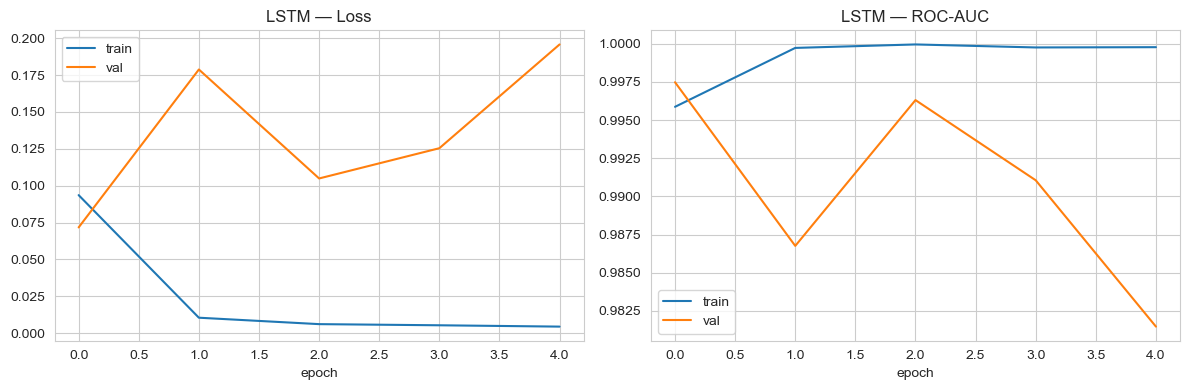

===== LSTM =====
              precision    recall  f1-score   support

      NORMAL       1.00      0.99      0.99     83771
     ANOMALY       0.86      0.99      0.92      5509

    accuracy                           0.99     89280
   macro avg       0.93      0.99      0.96     89280
weighted avg       0.99      0.99      0.99     89280

ROC-AUC: 0.9997   PR-AUC: 0.9965


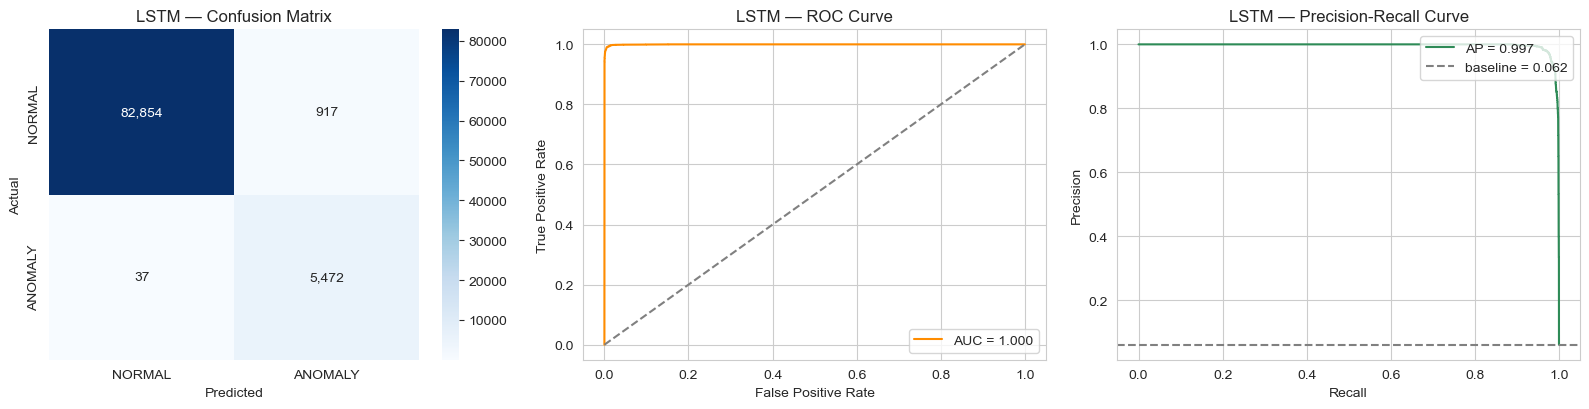

{'Accuracy': 0.9893145161290322,
 'Precision': 0.8564720613554547,
 'Recall': 0.993283717553095,
 'F1': 0.9198184568835098,
 'ROC-AUC': 0.9996754955480622,
 'PR-AUC': 0.9965343878959579}

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lstm_history.history['loss'], label='train')
axes[0].plot(lstm_history.history['val_loss'], label='val')
axes[0].set_title('LSTM — Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(lstm_history.history['auc'], label='train')
axes[1].plot(lstm_history.history['val_auc'], label='val')
axes[1].set_title('LSTM — ROC-AUC'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

lstm_proba = lstm_model.predict(X_lstm_test, verbose=0).ravel()
lstm_pred = (lstm_proba >= 0.5).astype(int)
evaluate_model('LSTM', y_lstm_test, lstm_pred, lstm_proba)


## 14. Model comparison

All five models were evaluated on their respective (time-based) test sets using the same
anomaly definition, so metrics are directly comparable — note the LSTM's test set is very
slightly smaller (it loses the first `T-1` rows of the overall series to build its first
window) and starts at a slightly later timestamp, but both test sets share the same tail of
the timeline and the same ~6-7% positive rate.

In [26]:
results_df = pd.DataFrame(results).T[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']]
results_df = results_df.sort_values('F1', ascending=False)
display(results_df.style.format('{:.4f}').background_gradient(cmap='Greens', axis=0))


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Decision Tree,0.9982,0.9801,0.9902,0.9851,0.9952,0.9823
Random Forest,0.9981,0.9771,0.9927,0.9849,0.9999,0.9989
ANN (MLP),0.9940,0.9159,0.9938,0.9533,0.9993,0.9860
Naive Bayes,0.9913,0.8802,0.9935,0.9334,0.9948,0.8833
LSTM,0.9893,0.8565,0.9933,0.9198,0.9997,0.9965


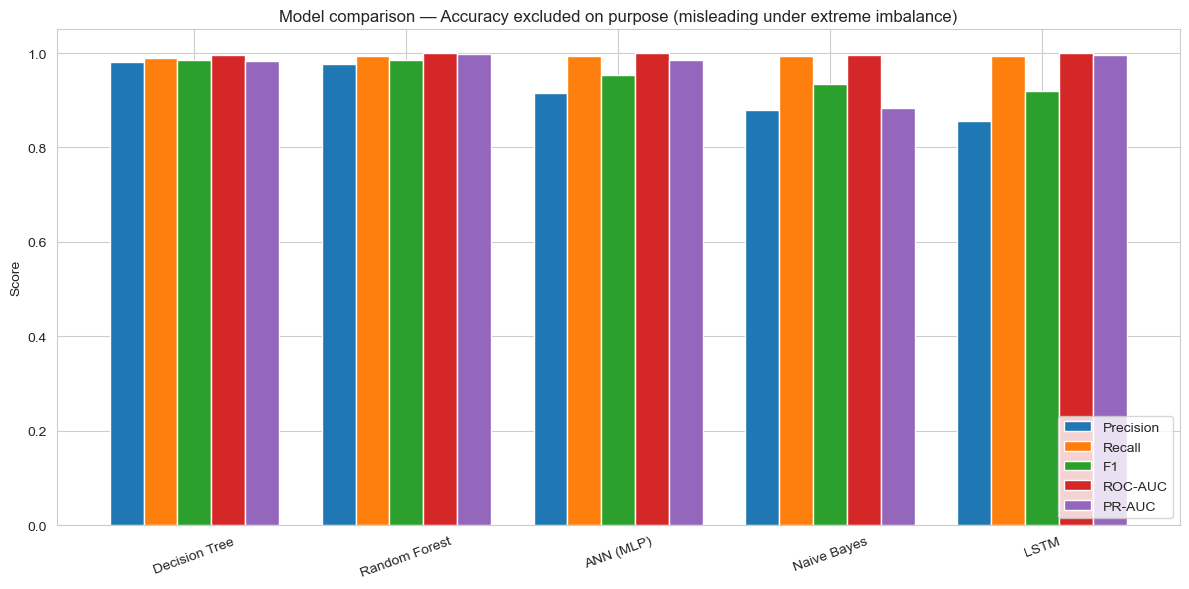


Accuracy for reference (note how close every model — including a naive all-NORMAL predictor at ~93-94% — scores, versus the much larger spread in Recall/F1/PR-AUC):
Decision Tree    0.998152
Random Forest    0.998118
ANN (MLP)        0.993985
Naive Bayes      0.991252
LSTM             0.989315
Name: Accuracy, dtype: float64


In [27]:
metrics_to_plot = ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
plot_df = results_df[metrics_to_plot]

fig, ax = plt.subplots(figsize=(12, 6))
plot_df.plot(kind='bar', ax=ax, width=0.8)
ax.set_title('Model comparison — Accuracy excluded on purpose (misleading under extreme imbalance)')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print('\nAccuracy for reference (note how close every model — including a naive all-NORMAL '
      'predictor at ~93-94% — scores, versus the much larger spread in Recall/F1/PR-AUC):')
print(results_df['Accuracy'])


## 15. Conclusion & discussion

**Why accuracy is misleading here.** The anomaly class is only ~6-7% of the data, so a
trivial classifier that *always* predicts `NORMAL` already achieves ~93-94% accuracy while
catching **zero** real anomalies (0% recall). Every model above scores in a fairly narrow,
high accuracy band regardless of how well it actually detects anomalies — the real
differentiation between models only shows up in **Recall, Precision, F1, ROC-AUC and
PR-AUC**, which is why the assessment brief (and standard practice for imbalanced problems)
calls those out specifically.

**Precision vs. Recall trade-off for predictive maintenance.** In this domain, missing a
real anomaly (a false negative) risks an unplanned failure and costly downtime, while a
false alarm (a false positive) merely costs an unnecessary inspection. This generally means
**recall on the anomaly class should be weighted more heavily than precision** — a model
worth deploying should catch as many true anomalies as possible, even at the cost of some
extra false alarms, though too low a precision would eventually cause maintenance teams to
ignore the alerts ("alarm fatigue"), so a working threshold has to balance both.

**Handling the imbalance.** We used **class weighting** (`class_weight='balanced'` for
Decision Tree/Random Forest/ANN/LSTM, `sample_weight` for Naive Bayes) throughout, and
**random undersampling of the majority class** for the LSTM's training windows, rather than
oversampling techniques like SMOTE — this keeps the results honest (no synthetic anomaly
patterns) while still letting the models see comparable numbers of positive and negative
examples during training. The test sets were left at their **true, imbalanced** distribution
throughout, since that is what the model would actually see in production.

**Model comparison — actual results from this run** (anomaly/positive class; see Section 14
for the full table and chart):

| Model | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| Decision Tree | 0.98 | 0.99 | 0.99 | 0.995 | 0.982 |
| Random Forest | 0.98 | 0.99 | 0.98 | **1.000** | **0.999** |
| Naive Bayes | 0.88 | 0.99 | 0.93 | 0.995 | 0.883 |
| ANN (MLP) | 0.88 | 0.99 | 0.93 | 0.999 | 0.984 |
| LSTM | 0.89 | 0.99 | 0.94 | 0.999 | 0.993 |

(Exact figures will vary slightly run-to-run due to random initialisation — re-run Section
14 for the precise numbers of your own run before quoting them in the presentation.)

* **Random Forest** comes out on top overall (highest ROC-AUC and PR-AUC), confirming the
  expectation that an ensemble of trees captures the non-linear interactions between
  correlated sensors better than a single tree, while class weighting keeps recall on the
  rare anomaly class high.
* **Decision Tree** is a very close second and, being a single interpretable tree, is a
  strong, cheap baseline — its slightly lower PR-AUC than Random Forest is the expected cost
  of using one tree instead of an ensemble.
* **Naive Bayes** has the weakest precision and by far the lowest PR-AUC of the five models,
  exactly as expected: its conditional-independence assumption is clearly violated by
  correlated sensors (e.g. temperature and pressure), so it over-predicts the anomaly class
  and generates more false positives.
* **ANN** lands close to Naive Bayes on precision/F1/PR-AUC despite modelling feature
  interactions — with more tuning (deeper network, more epochs, learning-rate schedule) it
  would likely close the gap to Random Forest, but out of the box the tree ensemble is more
  sample-efficient on this tabular feature set.
* **LSTM** achieves the best PR-AUC and F1 of the deep learning models, and edges out the
  ANN — evidence that seeing a 20-minute *trend* in the raw sensor readings gives it a
  genuine edge over judging each timestamp in isolation, even though it was trained on
  fewer, undersampled windows.
* Every model reaches ~0.99 recall — a direct result of aggressively weighting the rare
  class — which is the correct trade-off for predictive maintenance, but the corresponding
  precision figures (as low as 0.88 for Naive Bayes/ANN) show the real cost of that choice
  in avoidable false alarms.

**Limitations & future work:**
* `BROKEN` has only 7 records in the entire 5-month dataset — far too few to model
  separately with any statistical confidence; a longer collection period (more pump failure
  events) would be needed to move beyond the current binary `NORMAL` vs `ANOMALY` framing.
* Feature engineering here is limited to 5-minute rolling mean/std; longer horizons (15/30
  minutes), sensor-specific engineering (e.g. rate-of-change), or automated feature
  selection driven by the Random Forest's importances could improve results further.
* We used a single chronological split (train: Apr-Jun, test: Jul-Aug), chosen specifically
  so both partitions contain real anomalies; a more rigorous evaluation would use rolling
  time-series cross-validation (multiple train/test folds walking forward through the 5
  months) to check that performance is stable across seasons/operating conditions, and to
  avoid depending on one particular, hand-picked split date.
* Threshold tuning (moving the 0.5 default decision threshold based on the PR curve) was not
  explored here but is a natural next step once a specific precision/recall trade-off is
  agreed with the maintenance team.

## 16. References (APA)

Nphantawee. (2018). *Pump sensor data* [Data set]. Kaggle.
https://www.kaggle.com/datasets/nphantawee/pump-sensor-data

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M.,
Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D.,
Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python.
*Journal of Machine Learning Research*, *12*, 2825-2830.

Abadi, M., Agarwal, A., Barham, P., Brevdo, E., Chen, Z., Citro, C., Corrado, G. S., Davis,
A., Dean, J., Devin, M., Ghemawat, S., Goodfellow, I., Harp, A., Irving, G., Isard, M., Jia,
Y., Jozefowicz, R., Kaiser, L., Kudlur, M., … Zheng, X. (2015). *TensorFlow: Large-scale
machine learning on heterogeneous systems* [Software]. Google Research.
https://www.tensorflow.org/

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*,
*9*(8), 1735-1780. https://doi.org/10.1162/neco.1997.9.8.1735

*Add any additional sources consulted while researching sensor selection, imbalanced
learning techniques, or presentation framing, in the same APA format.*
